# Chapter 20: Case study: legged robots

A biped made of three rotation matrices, taken from a pendulum to a walking and turning gait
with impacts. The robot is the Reaction Mass Biped of Siravuru (2019, ch. 5): a telescoping
stance leg, a torso with three pairs of sliding reaction masses, and a swing leg.

This notebook is self-contained: NumPy, SciPy and Matplotlib only. Everything about the biped is
copied from the book's robot model library: the stance dynamics from its module
`reaction_mass_biped`, the integration step from `core`, and the impact map, the motion
primitive, the tracking laws and the walking loop from `biped_walking`. The book's verification
scripts check the originals.

Notation. $R$ maps body to world, $\dot R = R\,\Omega^\wedge$, $e_3$ points up and gravity acts
along $-e_3$. The attitudes of stance leg, torso and swing leg are `R1`, `RP`, `R2`, the length of
the stance leg is `l`, and `slide` holds the distances $r_i$ of the three pairs of reaction masses
from the hip. The input is $u = (f, \tau_1, \tau_P, \tau_2, f_s)$. Errors take the actual
configuration first.

In [1]:
from dataclasses import dataclass, field, replace

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

E1, E2, E3 = np.eye(3)
I3 = np.eye(3)
G = 9.81
PI = I3 - np.outer(E3, E3)                           # projection off the leg axis
PI_I = [I3 - np.outer(e, e) for e in np.eye(3)]      # projections off e_1, e_2, e_3
np.set_printoptions(precision=4, suppress=True)


def hat(x):
    """hat(x) y = x cross y."""
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(A):
    """Inverse of hat."""
    return np.array([A[2, 1], A[0, 2], A[1, 0]])


def expm_so3(x):
    """exp(hat(x)), Rodrigues' formula."""
    angle = np.linalg.norm(x)
    if angle < 1e-12:
        return I3 + hat(x)
    K = hat(x / angle)
    return I3 + np.sin(angle) * K + (1.0 - np.cos(angle)) * K @ K


def log_so3(R):
    """Rotation vector of R (away from half a turn)."""
    angle = np.arccos(np.clip((np.trace(R) - 1.0) / 2.0, -1.0, 1.0))
    if angle < 1e-9:
        return vee(R - R.T) / 2.0
    return angle * vee(R - R.T) / (2.0 * np.sin(angle))


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def Rz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)

## 1. The pendulum, with a deadline

A leg of fixed length is a 3D pendulum. The two feedback-linearizing laws of Chapter 6 (copied
from the verification script of Chapter 6) are run from rest, from a rotation by a given angle about a random axis,
and stopped at 0.35 s. At walking angles the two are hard to tell apart.

In [2]:
m_3, rho_3 = 1.0, np.array([0.0, 0.0, -0.5])
J_3 = np.diag([0.1625, 0.1625, 0.01])
J3inv = np.linalg.inv(J_3)
k_p, k_d = 100.0, 20.0


def grav_3(R):
    return m_3 * G * np.cross(R.T @ E3, rho_3)


def euler_zyx(R):
    return np.array([np.arctan2(R[1, 0], R[0, 0]), -np.arcsin(np.clip(R[2, 0], -1, 1)),
                     np.arctan2(R[2, 1], R[2, 2])])


def E_mat(th, ph):
    return np.array([[-np.sin(th), 0, 1], [np.cos(th) * np.sin(ph), np.cos(ph), 0],
                     [np.cos(th) * np.cos(ph), -np.sin(ph), 0]])


def E_dot(th, ph, th1, ph1):
    d_th = np.array([[-np.cos(th), 0, 0], [-np.sin(th) * np.sin(ph), 0, 0],
                     [-np.sin(th) * np.cos(ph), 0, 0]])
    d_ph = np.array([[0, 0, 0], [np.cos(th) * np.cos(ph), -np.sin(ph), 0],
                     [-np.cos(th) * np.sin(ph), -np.cos(ph), 0]])
    return d_th * th1 + d_ph * ph1


def tau_geo(R, Om):
    """Geometric feedback linearization: Omega_dot = -k_p e_R - k_d Omega (target Rd = I)."""
    return J_3 @ (-k_p * e_R(R, I3) - k_d * Om) + np.cross(Om, J_3 @ Om) - grav_3(R)


def tau_euler(R, Om):
    """Euler-angle feedback linearization: Theta_ddot = -k_p Theta - k_d Theta_dot."""
    Th = euler_zyx(R)
    Em = E_mat(Th[1], Th[2])
    Th1 = np.linalg.solve(Em, Om)
    return (J_3 @ (Em @ (-k_p * Th - k_d * Th1) + E_dot(Th[1], Th[2], Th1[1], Th1[2]) @ Th1)
            + np.cross(Om, J_3 @ Om) - grav_3(R))


def deadline_run(R0, law, deadline=0.35):
    """Angle left at the deadline (degrees) and peak torque (N·m), from rest."""
    def rhs(t, s):
        R, Om = s[:9].reshape(3, 3), s[9:12]
        return np.concatenate([(R @ hat(Om)).ravel(),
                               J3inv @ (law(R, Om) + grav_3(R) - np.cross(Om, J_3 @ Om))])
    ts = np.linspace(0.0, deadline, 141)
    sol = solve_ivp(rhs, [0, deadline], np.concatenate([R0.ravel(), np.zeros(3)]), t_eval=ts,
                    rtol=1e-8, atol=1e-10)
    Rs = sol.y[:9].T.reshape(-1, 3, 3)
    peak = max(np.linalg.norm(law(R, Om)) for R, Om in zip(Rs, sol.y[9:12].T))
    return np.degrees(np.arccos(np.clip((np.trace(Rs[-1]) - 1) / 2, -1, 1))), peak


rng = np.random.default_rng(20)
print("start   left geo  left Euler   peak geo  peak Euler")
for angle in (10, 30, 60, 120):
    rows = []
    for _ in range(8):
        axis = rng.normal(size=3)
        R0 = expm_so3(np.radians(angle) * axis / np.linalg.norm(axis))
        rows.append(deadline_run(R0, tau_geo) + deadline_run(R0, tau_euler))
    med = np.median(np.array(rows), axis=0)
    print(f"{angle:4d}°   {med[0]:6.1f}°   {med[2]:6.1f}°    {med[1]:6.1f}    {med[3]:6.1f}  N·m")

start   left geo  left Euler   peak geo  peak Euler


  10°      1.4°      1.4°       1.5       1.5  N·m


  30°      4.3°      4.1°       4.7       5.3  N·m


  60°     10.2°      8.5°       9.4      12.2  N·m


 120°     40.5°     17.0°       8.5      22.7  N·m


## 2. A robot made of three attitudes

The stance dynamics, copied from the library module `reaction_mass_biped`. With
$J(l) = J_0 + m l^2\Pi$ and $J_P(r) = J_P(0) + 2 m_r\sum_i r_i^2\Pi_i$:

$$m\ddot l = m l\,\Omega_1\cdot\Pi\Omega_1 - m g\,e_3\cdot R_1 e_3 + f,$$
$$J(l)\dot\Omega_1 + \Omega_1\times J(l)\Omega_1 + \dot J\Omega_1 = m g l\,(R_1^\top e_3)\times e_3 + \tau_1 - R_1^\top R_P\tau_P,$$
$$J_P(r)\dot\Omega_P + \Omega_P\times J_P(r)\Omega_P + \dot J_P\Omega_P = \tau_P - R_P^\top R_2\tau_2,$$
$$2 m_r\ddot r_i = 2 m_r r_i\,\Omega_P\cdot\Pi_i\Omega_P + f_{s,i},\qquad J_0\dot\Omega_2 + \Omega_2\times J_0\Omega_2 = \tau_2 .$$

In [3]:
@dataclass
class Params:
    """Mass properties chosen by Siravuru (2019, sec. 5.2)."""
    m_leg: float = 0.882
    m_r: float = 0.32
    J_0: np.ndarray = field(default_factory=lambda: 0.5 * np.diag([0.98, 0.91, 0.63]))
    J_P: np.ndarray = field(default_factory=lambda: np.array(
        [[0.2126, 0.0004, -0.0002], [0.0004, 0.2042, 0.0010], [-0.0002, 0.0010, 0.2246]]))
    g: float = G

    @property
    def m(self):
        return 2 * self.m_leg + 6 * self.m_r


@dataclass
class State:
    l: float
    l_dot: float
    R1: np.ndarray
    Omega1: np.ndarray
    RP: np.ndarray
    OmegaP: np.ndarray
    R2: np.ndarray
    Omega2: np.ndarray
    slide: np.ndarray
    slide_dot: np.ndarray


class Biped:
    """The part of the library's `reaction_mass_biped` that this notebook needs."""
    State = State
    params = Params()

    def torso_inertia(self, slide, params=None):
        p = params or self.params
        return p.J_P + 2 * p.m_r * sum(s**2 * P for s, P in zip(slide, PI_I))

    def dynamics(self, state, u, params=None):
        """(l_ddot, Omega1_dot, OmegaP_dot, Omega2_dot, slide_ddot)."""
        p = params or self.params
        f, tau_1, tau_P, tau_2, f_s = u
        R1, RP, R2, OmP, Om2 = state.R1, state.RP, state.R2, state.OmegaP, state.Omega2
        l, l_dot, Om1, m = state.l, state.l_dot, state.Omega1, p.m
        J1 = p.J_0 + m * l**2 * PI
        l_ddot = l * Om1 @ PI @ Om1 - p.g * E3 @ (R1 @ E3) + f / m
        Omega1_dot = np.linalg.solve(J1, m * p.g * l * np.cross(R1.T @ E3, E3) + tau_1
                                     - R1.T @ RP @ tau_P - np.cross(Om1, J1 @ Om1)
                                     - 2 * m * l * l_dot * PI @ Om1)
        JP = self.torso_inertia(state.slide, p)
        JP_dot = 4 * p.m_r * sum(s * sd * P for s, sd, P in zip(state.slide, state.slide_dot, PI_I))
        OmegaP_dot = np.linalg.solve(JP, tau_P - RP.T @ R2 @ tau_2 - np.cross(OmP, JP @ OmP)
                                     - JP_dot @ OmP)
        Omega2_dot = np.linalg.solve(p.J_0, tau_2 - np.cross(Om2, p.J_0 @ Om2))
        slide_ddot = np.array([s * OmP @ P @ OmP for s, P in zip(state.slide, PI_I)]) \
            + np.asarray(f_s) / (2 * p.m_r)
        return l_ddot, Omega1_dot, OmegaP_dot, Omega2_dot, slide_ddot

    def energy(self, state, params=None):
        p = params or self.params
        J1 = p.J_0 + p.m * state.l**2 * PI
        JP = self.torso_inertia(state.slide, p)
        return (0.5 * p.m * state.l_dot**2 + p.m_r * state.slide_dot @ state.slide_dot
                + 0.5 * state.Omega1 @ J1 @ state.Omega1 + 0.5 * state.OmegaP @ JP @ state.OmegaP
                + 0.5 * state.Omega2 @ p.J_0 @ state.Omega2
                + p.m * p.g * state.l * E3 @ (state.R1 @ E3))

    def on_manifold(self, state):
        return max(np.abs(R.T @ R - I3).max() for R in (state.R1, state.RP, state.R2))


biped = Biped()
PRM = biped.params
M_TOT = PRM.m
print("total mass", M_TOT, "kg")

total mass 3.684 kg


The integration step is the library's: classical Runge-Kutta stages on one increment per factor,
and the exponential update $R_{k+1} = R_k\exp(\cdot)$, so the attitudes stay on SO(3).

In [4]:
def _dexpinv(x, y):
    return y + 0.5 * np.cross(x, y) + np.cross(x, np.cross(x, y)) / 12.0

def fast_step(state, u, h, p=PRM):
    """The step of the library (Robot.step in its module core) written out for the biped:
    classical Runge-Kutta stages on one increment per factor, exponential update.
    The verification script of Chapter 20 checks that it gives the same states."""
    S = biped.State
    R1, RP, R2 = state.R1, state.RP, state.R2
    z = np.zeros(3)
    vel0 = (state.l_dot, state.Omega1, state.OmegaP, state.Omega2, state.slide_dot)

    def slope(inc, vel):
        at = S(l=state.l + inc[0], l_dot=vel[0], R1=R1 @ expm_so3(inc[1]), Omega1=vel[1],
               RP=RP @ expm_so3(inc[2]), OmegaP=vel[2], R2=R2 @ expm_so3(inc[3]), Omega2=vel[3],
               slide=state.slide + inc[4], slide_dot=vel[4])
        rates = (vel[0], _dexpinv(inc[1], vel[1]), _dexpinv(inc[2], vel[2]), _dexpinv(inc[3], vel[3]), vel[4])
        return rates, biped.dynamics(at, u, p)

    def add(a, b, s):
        return tuple(x + s * y for x, y in zip(a, b))

    zero = (0.0, z, z, z, z)
    k1 = slope(zero, vel0)
    k2 = slope(add(zero, k1[0], h / 2), add(vel0, k1[1], h / 2))
    k3 = slope(add(zero, k2[0], h / 2), add(vel0, k2[1], h / 2))
    k4 = slope(add(zero, k3[0], h), add(vel0, k3[1], h))
    inc = tuple(h / 6 * (a + 2 * b + 2 * c + d) for a, b, c, d in zip(k1[0], k2[0], k3[0], k4[0]))
    vel = tuple(v + h / 6 * (a + 2 * b + 2 * c + d) for v, a, b, c, d in zip(vel0, k1[1], k2[1], k3[1], k4[1]))
    return S(l=state.l + inc[0], l_dot=vel[0], R1=R1 @ expm_so3(inc[1]), Omega1=vel[1],
             RP=RP @ expm_so3(inc[2]), OmegaP=vel[2], R2=R2 @ expm_so3(inc[3]), Omega2=vel[3],
             slide=state.slide + inc[4], slide_dot=vel[4])

**The skater.** The torso spins with no torque on it. Forces along the rails pull the reaction
masses in from 25 cm to 5 cm. The angular momentum cannot change, so the spin rises by the ratio
of the inertias.

{'spin_start': 3.0, 'spin_end': 4.0104, 'inertia_ratio': 1.3371, 'momentum_error': 0.0, 'energy_gain': 0.4621, 'energy_gain_formula': 0.4621, 'J_start': 0.3046, 'J_end': 0.2278, 'slide_end': 0.05}


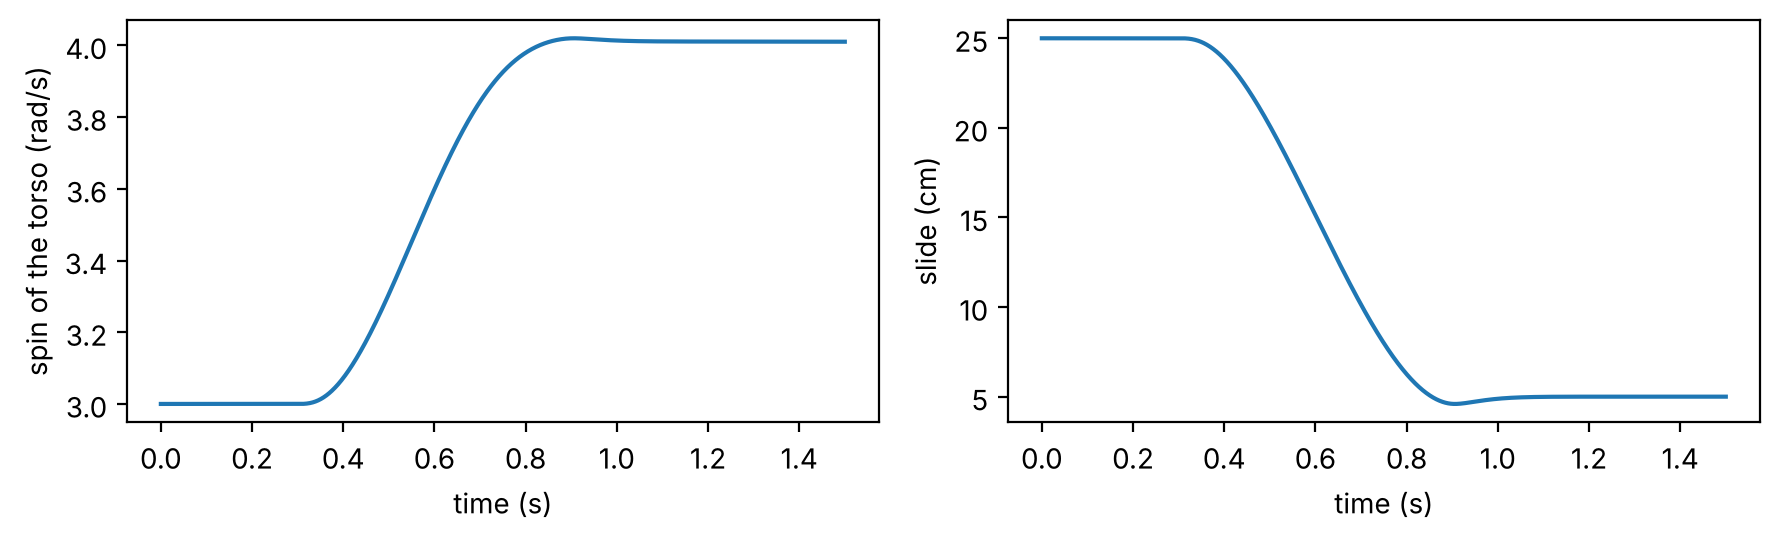

In [5]:
def skater(h=1e-3, t_f=1.5, spin=3.0, r_out=0.25, r_in=0.05):
    """The torso spins freely about the vertical while the slide forces pull the reaction
    masses in from r_out to r_in. No torque acts on the torso."""
    p = PRM
    st = biped.State(l=0.9, l_dot=0.0, R1=I3, Omega1=np.zeros(3), RP=I3, OmegaP=np.array([0.0, 0.0, spin]),
                     R2=I3, Omega2=np.zeros(3), slide=np.full(3, r_out), slide_dot=np.zeros(3))
    mom = lambda s: s.RP @ biped.torso_inertia(s.slide) @ s.OmegaP
    kin = lambda s: 0.5 * s.OmegaP @ biped.torso_inertia(s.slide) @ s.OmegaP + p.m_r * s.slide_dot @ s.slide_dot
    mom0, T0 = mom(st), kin(st)
    log = dict(t=[], slide=[], spin=[], RP=[], mom=[], J=[])
    n = int(round(t_f / h))
    for k in range(n + 1):
        t = k * h
        x = min(max((t - 0.3) / 0.6, 0.0), 1.0)
        blend = 3 * x**2 - 2 * x**3
        r_d = r_out + (r_in - r_out) * blend
        r_d_dot = (r_in - r_out) * (6 * x - 6 * x**2) / 0.6 if 0.0 < x < 1.0 else 0.0
        OmP = st.OmegaP
        f_s = (-2 * p.m_r * np.array([s * OmP @ P @ OmP for s, P in zip(st.slide, PI_I)])
               - 400.0 * (st.slide - r_d) - 30.0 * (st.slide_dot - r_d_dot))
        log["t"].append(t); log["slide"].append(st.slide.copy()); log["spin"].append(OmP[2]); log["RP"].append(st.RP)
        log["mom"].append(mom(st)[2]); log["J"].append(biped.torso_inertia(st.slide)[2, 2])
        if k < n:
            u = (p.m * G, np.zeros(3), np.zeros(3), np.zeros(3), f_s)
            st = fast_step(st, u, h)
    out = {k: np.array(v) for k, v in log.items()}
    out["summary"] = dict(spin_start=out["spin"][0], spin_end=out["spin"][-1],
                          inertia_ratio=out["J"][0] / out["J"][-1], momentum_error=float(np.abs(out["mom"] - mom0[2]).max()),
                          energy_gain=float(kin(st) - T0),
                          energy_gain_formula=float(0.5 * mom0[2]**2 * (1 / out["J"][-1] - 1 / out["J"][0])),
                          J_start=out["J"][0], J_end=out["J"][-1], slide_end=float(st.slide[0]))
    return out

sk = skater()
print({k: round(float(v), 4) for k, v in sk["summary"].items()})
fig, ax = plt.subplots(1, 2, figsize=(9, 2.8))
ax[0].plot(sk["t"], sk["spin"]); ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("spin of the torso (rad/s)")
ax[1].plot(sk["t"], 100 * sk["slide"][:, 0]); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("slide (cm)")
plt.tight_layout(); plt.show()

## 3. Touchdown

The swing foot lands and sticks. Only the swing leg and the hip velocity change:

$$J(l_0)\,\Omega_2^+ = J_0\,\Omega_2^- + m\,l_0\; e_3\times R_2^\top v_P^{-},\qquad
v_P^{+} = l_0 R_2(\Omega_2^+\times e_3),\qquad p_c = m\,(v_P^{+} - v_P^{-}).$$

Then the legs trade names. The functions are copied from the library module `biped_walking`.
The cell checks the conservation law behind the first equation: the angular momentum about the
landing foot, summed mass by mass.

In [6]:
def hip_velocity(l, l_dot, R1, Omega1):
    """Velocity of the hip x_P = l R1 e3 in stance."""
    return l_dot * R1 @ E3 + l * R1 @ np.cross(Omega1, E3)

def swing_foot(state, l_0):
    """Position of the swing foot relative to the stance foot."""
    return state.l * state.R1 @ E3 - l_0 * state.R2 @ E3

def impact(state, l_0, p=PRM):
    """The swing foot lands and sticks: eq20-impact.

    Returns (new stance state, impulse on the foot, step vector). Only the swing
    leg and the hip velocity change:
        J(l_0) Omega2+ = J_0 Omega2- + m l_0 e3 x R2^T v_P-,   J(l) = J_0 + m l^2 Pi,
        v_P+ = l_0 R2 (Omega2+ x e3),      impulse = m (v_P+ - v_P-).
    Then the legs trade names: the old swing leg is the new stance leg.
    """
    m = p.m
    v_minus = hip_velocity(state.l, state.l_dot, state.R1, state.Omega1)
    J_c = p.J_0 + m * l_0**2 * PI
    Omega2_plus = np.linalg.solve(J_c, p.J_0 @ state.Omega2 + m * l_0 * np.cross(E3, state.R2.T @ v_minus))
    v_plus = l_0 * state.R2 @ np.cross(Omega2_plus, E3)
    new = replace(state, l=l_0, l_dot=0.0, R1=state.R2, Omega1=Omega2_plus,
                  R2=state.R1, Omega2=state.Omega1)
    return new, m * (v_plus - v_minus), swing_foot(state, l_0)

def particles(state, v_P, p=PRM):
    """The point masses of the floating-base model: (mass, position from the hip, velocity)."""
    out = [(2 * p.m_leg, np.zeros(3), v_P)]
    for i in range(3):
        a = state.RP[:, i]
        a_dot = state.RP @ np.cross(state.OmegaP, np.eye(3)[i])
        for sign in (1.0, -1.0):
            out.append((p.m_r, sign * state.slide[i] * a,
                        v_P + sign * (state.slide_dot[i] * a + state.slide[i] * a_dot)))
    return out

def angular_momentum_about(point_from_hip, state, v_P, Omega1, OmegaP, Omega2, p=PRM):
    """World-frame angular momentum about a point, built mass by mass."""
    H = state.R1 @ p.J_0 @ Omega1 + state.RP @ p.J_P @ OmegaP + state.R2 @ p.J_0 @ Omega2
    for mass, r, v in particles(replace(state, OmegaP=OmegaP), v_P, p):
        H = H + mass * np.cross(r - point_from_hip, v)
    return H

rng = np.random.default_rng(1)
st = State(l=0.95, l_dot=-0.3, R1=expm_so3(0.3 * rng.normal(size=3)), Omega1=rng.normal(size=3),
           RP=expm_so3(rng.normal(size=3)), OmegaP=rng.normal(size=3),
           R2=expm_so3(0.3 * rng.normal(size=3)), Omega2=rng.normal(size=3),
           slide=np.array([0.1, 0.12, 0.15]), slide_dot=0.1 * rng.normal(size=3))
new, p_c, stride = impact(st, 0.9)
c = -0.9 * st.R2 @ E3                                    # the landing foot, seen from the hip
v_minus = hip_velocity(st.l, st.l_dot, st.R1, st.Omega1)
v_plus = hip_velocity(new.l, new.l_dot, new.R1, new.Omega1)
H_minus = angular_momentum_about(c, st, v_minus, st.Omega1, st.OmegaP, st.Omega2)
H_plus = angular_momentum_about(c, st, v_plus, st.Omega1, st.OmegaP, new.Omega1)
print("impulse on the foot       ", p_c, "N·s")
print("angular momentum, before  ", H_minus)
print("angular momentum, after   ", H_plus)
print("energy lost               ", biped.energy(st) - biped.energy(new), "J")

impulse on the foot        [-0.355  -0.9287  0.4479] N·s
angular momentum, before   [-4.8279  2.4366 -0.3146]
angular momentum, after    [-4.8279  2.4366 -0.3146]
energy lost                2.5137490494964823 J


## 4. Walking and turning

The motion primitive of one step, the tracking law of the thesis (its eqs. 5.61 to 5.65, with
gravity along $-e_3$ and its gains of Table 5.3), and the hybrid loop: integrate the stance
dynamics, detect the touchdown of the swing foot, apply the impact map, start the next step.
The code is copied from the library module `biped_walking`, with the library's step written
out as `fast_step`.

In [7]:
@dataclass
class Gait:
    l_0: float = 0.9                    # nominal leg length, m        (thesis rho_0)
    l_bar: float = 0.1                  # leg extension in mid-stance  (thesis rho_bar)
    r_0: float = 0.125                  # nominal slide, m             (thesis s)
    r_bar: float = 0.025                # slide excursion, m           (thesis s_bar)
    t_s: float = 1.0                    # duration of the primitive, s (thesis T)
    theta_s: float = np.radians(15.0)   # legs swing from -15 to 15 degrees
    lean: float = np.radians(10.0)      # torso pitch, forward (our choice)
    roll: float = 0.0                   # torso roll into a turn

def primitive(t, psi, gait):
    """Desired stance state and accelerations at time t of a step with heading psi."""
    w = np.pi / gait.t_s
    th_s = gait.theta_s
    th = -th_s + 2 * th_s * np.sin(w * t / 2)
    th1 = th_s * w * np.cos(w * t / 2)
    th2 = -0.5 * th_s * w**2 * np.sin(w * t / 2)
    Rpsi = Rz(psi)
    one = np.ones(3)
    return dict(
        l=gait.l_0 + gait.l_bar * np.sin(w * t), l_dot=gait.l_bar * w * np.cos(w * t),
        l_ddot=-gait.l_bar * w**2 * np.sin(w * t),
        R1=Rpsi @ Ry(th), Omega1=th1 * E2, Omega1_dot=th2 * E2,
        R2=Rpsi @ Ry(-th), Omega2=-th1 * E2, Omega2_dot=-th2 * E2,
        RP=Rpsi @ Rx(gait.roll) @ Ry(gait.lean), OmegaP=np.zeros(3), OmegaP_dot=np.zeros(3),
        slide=(gait.r_0 + gait.r_bar * np.sin(w * t)) * one,
        slide_dot=gait.r_bar * w * np.cos(w * t) * one,
        slide_ddot=-gait.r_bar * w**2 * np.sin(w * t) * one)

def primitive_state(t, psi, gait):
    d = primitive(t, psi, gait)
    return biped.State(l=d["l"], l_dot=d["l_dot"], R1=d["R1"], Omega1=d["Omega1"], RP=d["RP"],
                       OmegaP=d["OmegaP"], R2=d["R2"], Omega2=d["Omega2"], slide=d["slide"],
                       slide_dot=d["slide_dot"])

@dataclass
class ThesisGains:
    """Table 5.3 of the thesis with eps = 0.25. The table lists L and no D_P: we use
    L as the torso damping."""
    eps: float = 0.25

    @property
    def k_l(self):
        return 16 / self.eps**2

    @property
    def k_ldot(self):
        return 8 / self.eps

    @property
    def D(self):
        return np.array([1.2, 1.5, 1.8]) / self.eps**2

    @property
    def k_Omega(self):
        """Damping of the stance leg, the torso and the swing leg."""
        return 2 / self.eps, 1.5 * 1.2, 0.5 / self.eps

    @property
    def k_r(self):
        return 1.2 / self.eps**2

    @property
    def k_rdot(self):
        return 1.5 / self.eps

def Psi_right(R, Rd, D):
    """tr(D (I - R Rd^T)): the weighted error function of the thesis."""
    return float(np.sum(D * (1.0 - np.diag(R @ Rd.T))))

def e_right(R, Rd, D):
    """Slope of Psi_right under delta R = R hat(eta): sum_i d_i (R^T e_i) x (Rd^T e_i)."""
    return sum(D[i] * np.cross(R[i, :], Rd[i, :]) for i in range(3))

def torso_inertia_rate(slide, slide_dot, p=PRM):
    return 4 * p.m_r * sum(s * sd * P for s, sd, P in zip(slide, slide_dot, PI_I))

def _stack(n_1, n_P, n_2, state):
    """Joint torques (tau_1, tau_P, tau_2) that put the net torques n on the bodies."""
    tau_2 = n_2
    tau_P = n_P + state.RP.T @ state.R2 @ tau_2
    tau_1 = n_1 + state.R1.T @ state.RP @ tau_P
    return tau_1, tau_P, tau_2

def thesis_law(state, d, gains=ThesisGains(), p=PRM):
    """Thesis eqs. (5.61) to (5.65) with Phi the identity, gravity along -e3."""
    m, D = p.m, gains.D
    k1, kP, k2 = gains.k_Omega
    l, l_dot, R1, Om1 = state.l, state.l_dot, state.R1, state.Omega1
    f = (m * d["l_ddot"] - m * l * Om1 @ PI @ Om1 + m * G * E3 @ (R1 @ E3)
         - gains.k_l * (l - d["l"]) - gains.k_ldot * (l_dot - d["l_dot"]))
    J1 = p.J_0 + m * l**2 * PI
    n_1 = (J1 @ d["Omega1_dot"] + np.cross(d["Omega1"], J1 @ Om1)
           - m * G * l * np.cross(R1.T @ E3, E3) + m * l * l_dot * PI @ (Om1 + d["Omega1"])
           - e_right(R1, d["R1"], D) - k1 * (Om1 - d["Omega1"]))
    JP = biped.torso_inertia(state.slide, p)
    JP_dot = torso_inertia_rate(state.slide, state.slide_dot, p)
    OmP = state.OmegaP
    n_P = (np.cross(d["OmegaP"], JP @ OmP) + JP @ d["OmegaP_dot"] + 0.5 * JP_dot @ (OmP + d["OmegaP"])
           - e_right(state.RP, d["RP"], D) - kP * (OmP - d["OmegaP"]))
    Om2 = state.Omega2
    n_2 = (np.cross(d["Omega2"], p.J_0 @ Om2) + p.J_0 @ d["Omega2_dot"]
           - e_right(state.R2, d["R2"], D) - k2 * (Om2 - d["Omega2"]))
    f_s = (2 * p.m_r * d["slide_ddot"]
           - 2 * p.m_r * np.array([s * OmP @ P @ OmP for s, P in zip(state.slide, PI_I)])
           - gains.k_r * (state.slide - d["slide"]) - gains.k_rdot * (state.slide_dot - d["slide_dot"]))
    tau_1, tau_P, tau_2 = _stack(n_1, n_P, n_2, state)
    return f, tau_1, tau_P, tau_2, f_s

def thesis_V(state, d, gains=ThesisGains(), p=PRM):
    """The Lyapunov function of the thesis, eq. (5.66), with Phi the identity."""
    m, D = p.m, gains.D
    J1 = p.J_0 + m * state.l**2 * PI
    JP = biped.torso_inertia(state.slide, p)
    w1, wP, w2 = state.Omega1 - d["Omega1"], state.OmegaP - d["OmegaP"], state.Omega2 - d["Omega2"]
    rt, rt_dot = state.slide - d["slide"], state.slide_dot - d["slide_dot"]
    return (0.5 * m * (state.l_dot - d["l_dot"])**2 + 0.5 * gains.k_l * (state.l - d["l"])**2
            + 0.5 * w1 @ J1 @ w1 + Psi_right(state.R1, d["R1"], D)
            + 0.5 * wP @ JP @ wP + p.m_r * rt_dot @ rt_dot + 0.5 * gains.k_r * rt @ rt
            + Psi_right(state.RP, d["RP"], D)
            + 0.5 * w2 @ p.J_0 @ w2 + Psi_right(state.R2, d["R2"], D))

In [8]:
@dataclass
class BookGains:
    """Scalar gains for eq6-law on each factor, matched to the thesis gains near zero error."""
    k_l: float = 256.0
    k_ldot: float = 32.0
    k_R: tuple = (48.0, 48.0, 48.0)          # stance leg, torso, swing leg
    k_Omega: tuple = (8.0, 1.8, 2.0)
    k_r: float = 19.2
    k_rdot: float = 6.0
    half_rate: bool = True                   # the term -(1/2) J_dot e_Omega
    feedforward: bool = True

def book_e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)

def book_law(state, d, gains=BookGains(), p=PRM):
    """eq6-law on each of the three factors, with the gravity torque canceled and the
    two terms that a configuration-dependent inertia adds: + J_dot Omega - (1/2) J_dot e_Omega."""
    m = p.m
    ff = 1.0 if gains.feedforward else 0.0
    l, l_dot, R1 = state.l, state.l_dot, state.R1
    f = (ff * m * d["l_ddot"] - m * l * state.Omega1 @ PI @ state.Omega1 + m * G * E3 @ (R1 @ E3)
         - gains.k_l * (l - d["l"]) - gains.k_ldot * (l_dot - ff * d["l_dot"]))
    J1 = p.J_0 + m * l**2 * PI
    J1_dot = 2 * m * l * l_dot * PI
    JP = biped.torso_inertia(state.slide, p)
    JP_dot = torso_inertia_rate(state.slide, state.slide_dot, p)
    n = []
    for i, (R, Om, J, J_dot, key) in enumerate(((R1, state.Omega1, J1, J1_dot, "1"),
                                                 (state.RP, state.OmegaP, JP, JP_dot, "P"),
                                                 (state.R2, state.Omega2, p.J_0, 0 * I3, "2"))):
        Rd, Omd, Omd_dot = d["R" + key], ff * d["Omega" + key], ff * d["Omega" + key + "_dot"]
        e_Omega = Om - R.T @ Rd @ Omd
        tau = (-gains.k_R[i] * book_e_R(R, Rd) - gains.k_Omega[i] * e_Omega
               + np.cross(Om, J @ Om) - J @ (np.cross(Om, R.T @ Rd @ Omd) - R.T @ Rd @ Omd_dot)
               + J_dot @ Om - (0.5 * J_dot @ e_Omega if gains.half_rate else 0.0))
        n.append(tau)
    n[0] = n[0] - m * G * l * np.cross(R1.T @ E3, E3)
    OmP = state.OmegaP
    f_s = (ff * 2 * p.m_r * d["slide_ddot"]
           - 2 * p.m_r * np.array([s * OmP @ P @ OmP for s, P in zip(state.slide, PI_I)])
           - gains.k_r * (state.slide - d["slide"]) - gains.k_rdot * (state.slide_dot - ff * d["slide_dot"]))
    tau_1, tau_P, tau_2 = _stack(n[0], n[1], n[2], state)
    return f, tau_1, tau_P, tau_2, f_s

def book_V0(state, d, gains=BookGains(), p=PRM):
    """Sum over the factors of eq6-V0, plus the two PD energies of the lengths."""
    m = p.m
    J1 = p.J_0 + m * state.l**2 * PI
    JP = biped.torso_inertia(state.slide, p)
    V = 0.5 * m * (state.l_dot - d["l_dot"])**2 + 0.5 * gains.k_l * (state.l - d["l"])**2
    rt, rt_dot = state.slide - d["slide"], state.slide_dot - d["slide_dot"]
    V += p.m_r * rt_dot @ rt_dot + 0.5 * gains.k_r * rt @ rt
    rate = -gains.k_ldot * (state.l_dot - d["l_dot"])**2 - gains.k_rdot * rt_dot @ rt_dot
    for i, (R, Om, J, key) in enumerate(((state.R1, state.Omega1, J1, "1"), (state.RP, state.OmegaP, JP, "P"),
                                         (state.R2, state.Omega2, p.J_0, "2"))):
        Rd = d["R" + key]
        e_Omega = Om - R.T @ Rd @ d["Omega" + key]
        V += 0.5 * e_Omega @ J @ e_Omega + gains.k_R[i] * 0.5 * np.trace(I3 - Rd.T @ R)
        rate += -gains.k_Omega[i] * e_Omega @ e_Omega
    return V, rate

def hip_acceleration(state, acc):
    """Second derivative of x_P = l R1 e3 from the stance accelerations."""
    l, ld, R, Om = state.l, state.l_dot, state.R1, state.Omega1
    l_dd, Om_d = acc[0], acc[1]
    return R @ (l_dd * E3 + 2 * ld * np.cross(Om, E3)
                + l * (np.cross(Om_d, E3) + np.cross(Om, np.cross(Om, E3))))

def attitude_angle(R, Rd):
    return float(np.linalg.norm(log_so3(Rd.T @ R)))

def walk(headings, gait=Gait(), law=thesis_law, gains=None, h=1e-3, state0=None, rolls=None,
         max_step_time=3.0, p=PRM, record=5):
    """Walk len(headings) steps. Step i tracks the primitive with heading headings[i]; it
    ends when the swing foot comes down to the ground, where the impact map is applied.

    The controller is sampled every h and held (the library's step). Returns a dict of
    arrays sampled every h and a list of per-step summaries."""
    gains = gains if gains is not None else (ThesisGains() if law is thesis_law else BookGains())
    state = state0 if state0 is not None else primitive_state(0.0, headings[0], gait)
    foot = np.zeros(3)
    log = {k: [] for k in ("t", "step", "hip", "foot", "swing", "R1", "RP", "R2", "l", "slide", "e_l", "e_r",
                           "a1", "aP", "a2", "V", "F", "tau_1", "tau_P", "tau_2", "f", "E", "H_foot", "ts")}
    steps, t0 = [], 0.0
    peak = dict(tau_1=np.zeros(3), tau_P=np.zeros(3), tau_2=np.zeros(3))
    for i, psi in enumerate(headings):
        g_i = gait if rolls is None else replace(gait, roll=rolls[i])
        ts, done, count = 0.0, False, 0
        clearance, e_start = np.inf, None
        while not done:
            d = primitive(ts, psi, g_i)
            u = law(state, d, gains, p)
            for key, val in zip(("tau_1", "tau_P", "tau_2"), u[1:4]):
                peak[key] = np.maximum(peak[key], np.abs(val))
            count += 1
            if record and (count - 1) % record == 0:
                acc = biped.dynamics(state, u, p)
                F = M_TOT * (hip_acceleration(state, acc) + G * E3)
                hip = foot + state.l * state.R1 @ E3
                vP = hip_velocity(state.l, state.l_dot, state.R1, state.Omega1)
                for k, val in (("t", t0 + ts), ("step", i), ("hip", hip), ("foot", foot.copy()),
                               ("swing", foot + swing_foot(state, gait.l_0)), ("R1", state.R1),
                               ("RP", state.RP), ("R2", state.R2), ("l", state.l), ("slide", state.slide.copy()),
                               ("e_l", state.l - d["l"]), ("e_r", np.linalg.norm(state.slide - d["slide"])),
                               ("a1", attitude_angle(state.R1, d["R1"])), ("aP", attitude_angle(state.RP, d["RP"])),
                               ("a2", attitude_angle(state.R2, d["R2"])),
                               ("V", thesis_V(state, d, gains, p) if law is thesis_law else book_V0(state, d, gains, p)[0]),
                               ("F", F), ("tau_1", u[1]), ("tau_P", u[2]), ("tau_2", u[3]), ("f", u[0]),
                               ("E", biped.energy(state, p)),
                               ("H_foot", angular_momentum_about(state.l * state.R1 @ E3, state, vP, state.Omega1,
                                                                 state.OmegaP, state.Omega2, p)),
                               ("ts", ts)):
                    log[k].append(val)
            if e_start is None:
                e_start = (attitude_angle(state.R1, d["R1"]), attitude_angle(state.R2, d["R2"]))
            new = fast_step(state, u, h, p)
            z0, z1 = swing_foot(state, gait.l_0)[2], swing_foot(new, gait.l_0)[2]
            if ts > 0.5 * gait.t_s and z1 <= 0.0 < z0:
                lo, hi = 0.0, h                               # bisect for the touchdown time
                for _ in range(50):
                    mid = 0.5 * (lo + hi)
                    if swing_foot(fast_step(state, u, mid, p), gait.l_0)[2] > 0.0:
                        lo = mid
                    else:
                        hi = mid
                state, ts, done = fast_step(state, u, hi, p), ts + hi, True
            else:
                if 0.1 * gait.t_s < ts < 0.9 * gait.t_s:
                    clearance = min(clearance, z1)
                state, ts = new, ts + h
                if ts > max_step_time:
                    raise RuntimeError(f"step {i}: no touchdown within {max_step_time} s")
        d = primitive(ts, psi, g_i)
        pre = state
        E_minus = biped.energy(pre, p)
        state, impulse, stride = impact(pre, gait.l_0, p)
        steps.append(dict(step_time=ts, step_vector=stride, step_length=float(np.linalg.norm(stride[:2])),
                          foot_height_error=float(stride[2]), impulse=impulse, clearance=clearance,
                          e_start=e_start, e_end=(attitude_angle(pre.R1, d["R1"]), attitude_angle(pre.R2, d["R2"])),
                          energy_lost=E_minus - biped.energy(state, p), pre=pre, post=state, foot=foot.copy()))
        foot = foot + np.array([stride[0], stride[1], 0.0])
        t0 += ts
    out = {k: np.array(v) for k, v in log.items()}
    out["final_state"], out["final_foot"], out["peak"] = state, foot, peak
    return out, steps

def turn_plan():
    """Headings and torso rolls of the turn: four steps straight, six steps that add
    15 degrees each with the torso rolled 20 degrees into the turn, four steps straight."""
    hd = [0.0] * 4 + list(np.radians(15.0) * np.arange(1, 7)) + [np.radians(90.0)] * 4
    rolls = [0.0] * 4 + [np.radians(-20.0)] * 6 + [0.0] * 4
    return hd, rolls

step 1: length 46.62 cm, time 1.000 s, impulse [-0.185  0.     0.987] N·s, energy lost 0.142 J
step 2: length 48.77 cm, time 0.986 s, impulse [-0.494  0.     1.489] N·s, energy lost 0.341 J
step 3: length 48.99 cm, time 0.991 s, impulse [-0.433  0.     1.352] N·s, energy lost 0.276 J
step 4: length 49.14 cm, time 0.988 s, impulse [-0.453  0.     1.393] N·s, energy lost 0.295 J
step 5: length 49.13 cm, time 0.989 s, impulse [-0.447  0.     1.381] N·s, energy lost 0.289 J
step 6: length 49.14 cm, time 0.989 s, impulse [-0.449  0.     1.385] N·s, energy lost 0.291 J


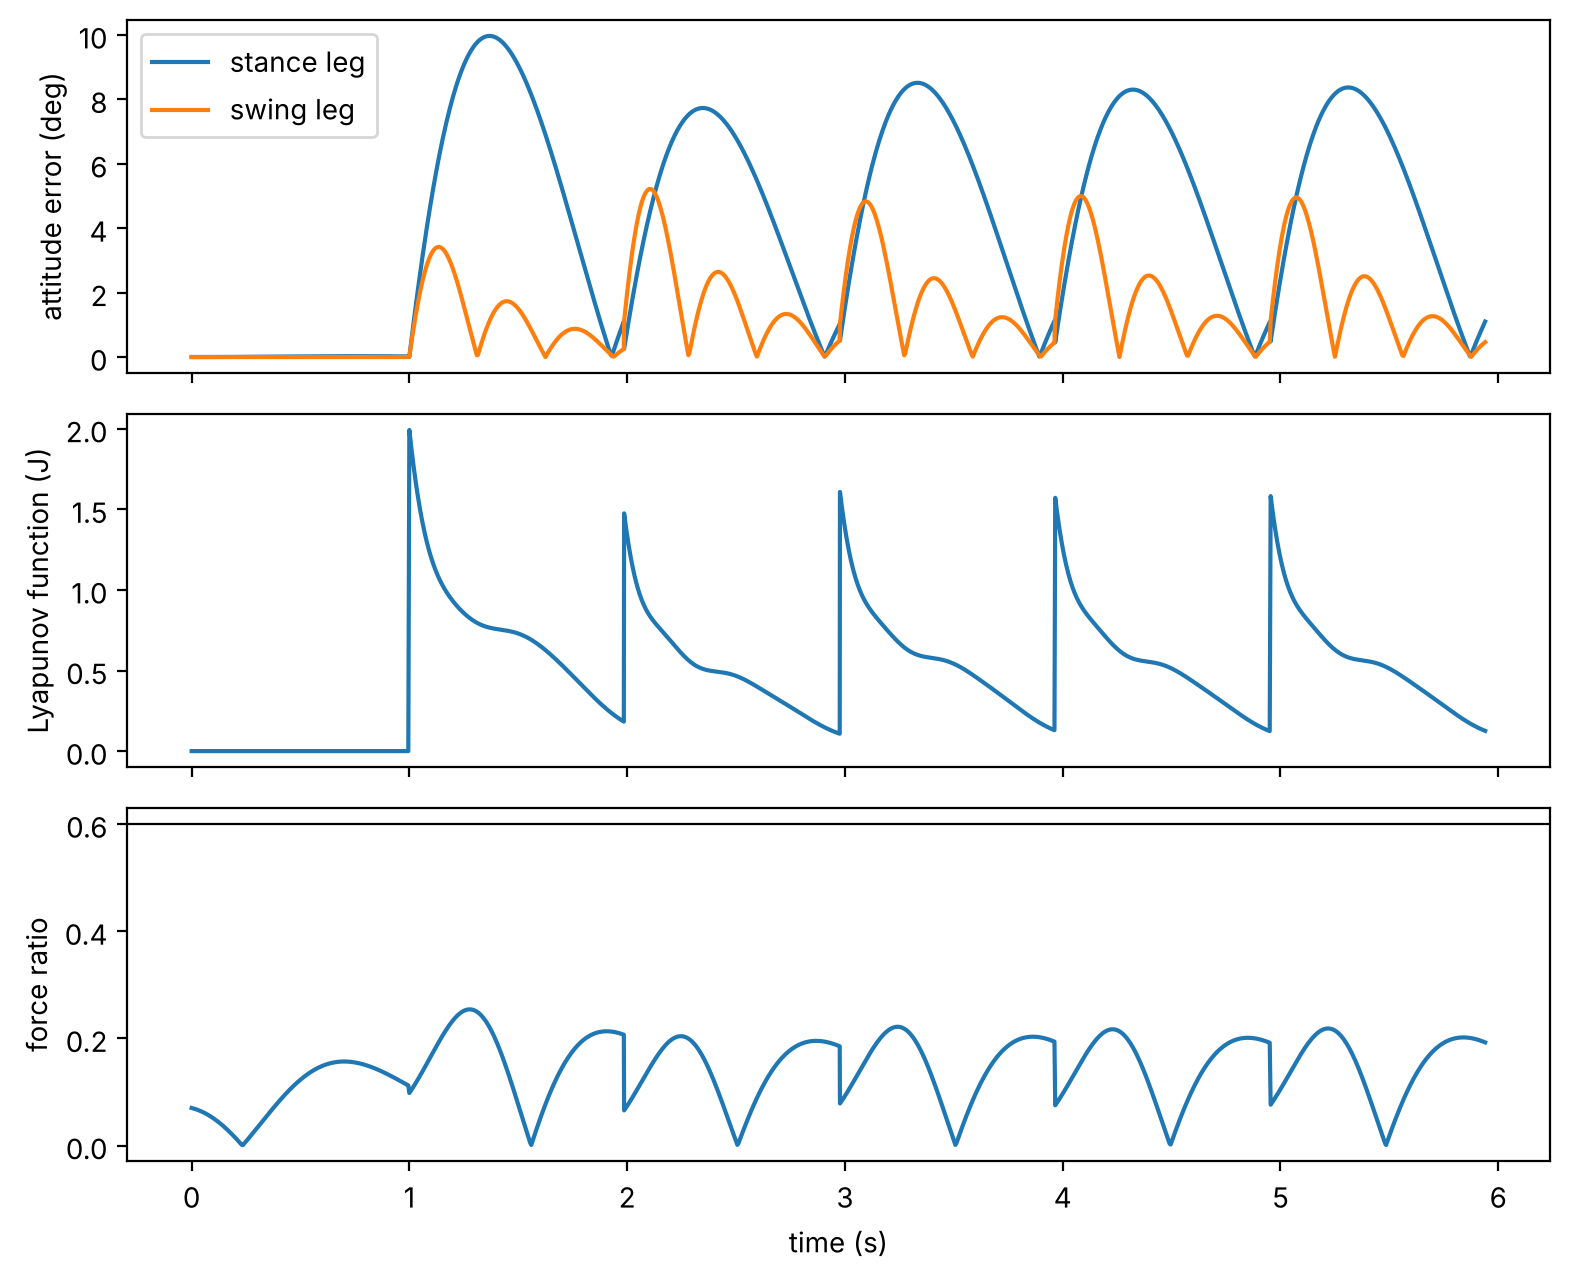

In [9]:
o, steps = walk([0.0] * 6)
for k, s in enumerate(steps):
    print(f"step {k + 1}: length {100 * s['step_length']:.2f} cm, time {s['step_time']:.3f} s, "
          f"impulse {np.round(s['impulse'], 3)} N·s, energy lost {s['energy_lost']:.3f} J")

fig, ax = plt.subplots(3, 1, figsize=(8, 6.5), sharex=True)
ax[0].plot(o["t"], np.degrees(o["a1"]), label="stance leg")
ax[0].plot(o["t"], np.degrees(o["a2"]), label="swing leg")
ax[0].set_ylabel("attitude error (deg)"); ax[0].legend()
ax[1].plot(o["t"], o["V"]); ax[1].set_ylabel("Lyapunov function (J)")
F = o["F"]
ax[2].plot(o["t"], np.linalg.norm(F[:, :2], axis=1) / F[:, 2]); ax[2].axhline(0.6, color="k", lw=0.8)
ax[2].set_ylabel("force ratio"); ax[2].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

**The turn.** Four steps straight, six steps in which the heading of the reference jumps by 15°
at each touchdown, four steps straight. This cell takes about half a minute.

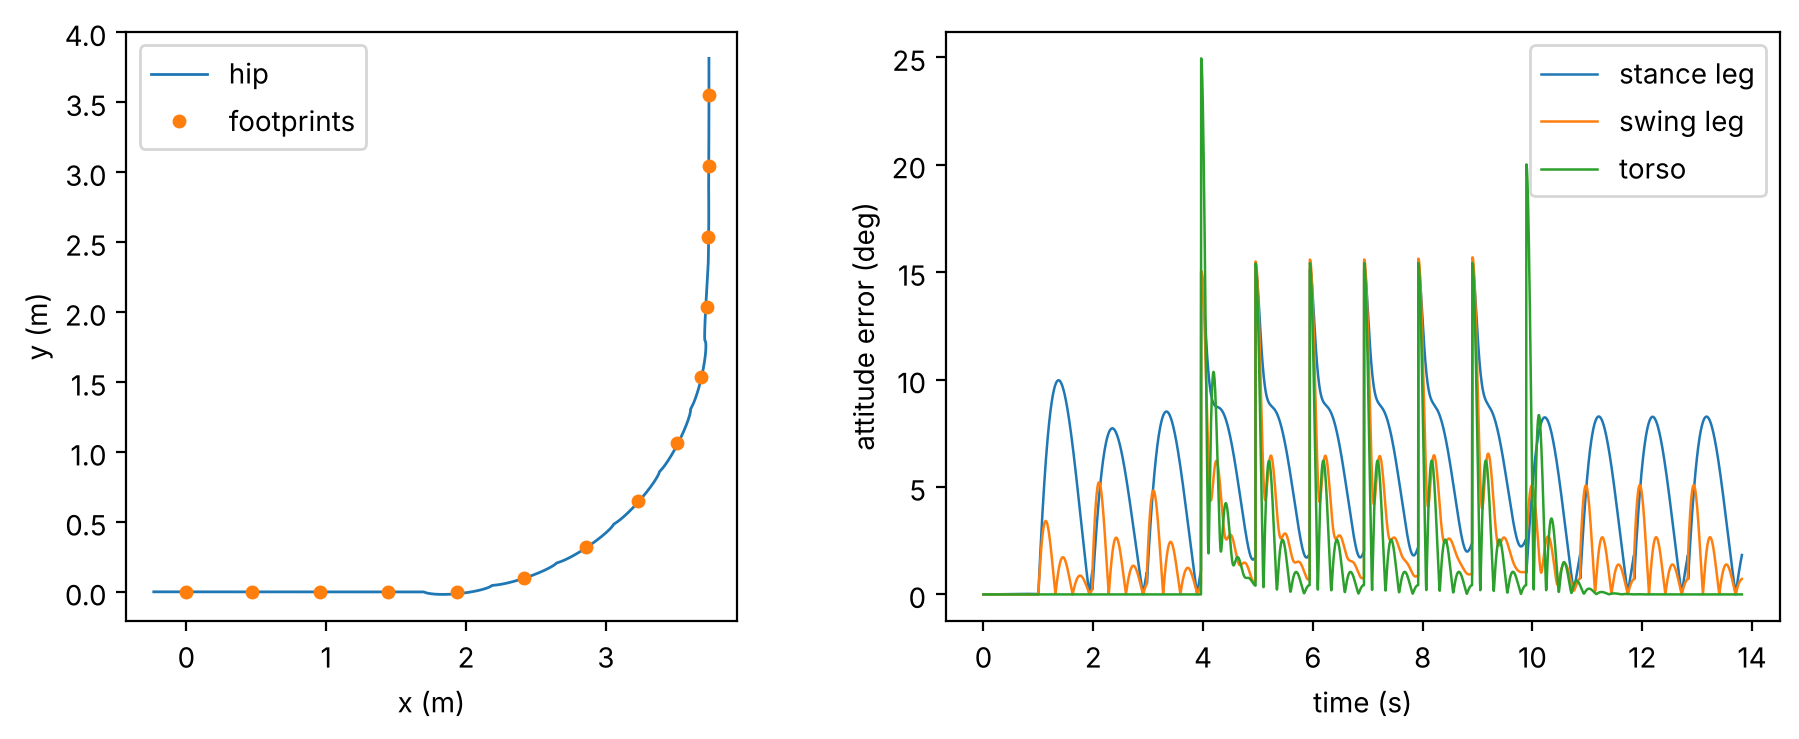

peak ankle torque about e1, e2, e3: [15.9 16.6 36.8] N·m
largest distance from SO(3): 2.220446049250313e-14


In [10]:
hd, rolls = turn_plan()
ot, stepst = walk(hd, rolls=rolls)
feet = np.array([s["foot"] for s in stepst])
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
ax[0].plot(ot["hip"][:, 0], ot["hip"][:, 1], lw=1.0, label="hip")
ax[0].plot(feet[:, 0], feet[:, 1], "o", ms=4, label="footprints")
ax[0].set_aspect("equal"); ax[0].set_xlabel("x (m)"); ax[0].set_ylabel("y (m)"); ax[0].legend()
for key, name in (("a1", "stance leg"), ("a2", "swing leg"), ("aP", "torso")):
    ax[1].plot(ot["t"], np.degrees(ot[key]), lw=0.9, label=name)
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("attitude error (deg)"); ax[1].legend()
plt.tight_layout(); plt.show()
print("peak ankle torque about e1, e2, e3:", np.round(ot["peak"]["tau_1"], 1), "N·m")
print("largest distance from SO(3):", biped.on_manifold(ot["final_state"]))

## 5. What each choice bought

The thesis weights the error $R R_d^\top$, so its weights belong to world axes, and the settled
step depends on the heading. With `book_law` (the attitude law of Chapter 6 on each factor, scalar
gains) it does not.

In [11]:
for name, law in (("thesis law", thesis_law), ("scalar gains", book_law)):
    for psi in (0.0, np.pi / 2):
        _, st_ = walk([psi] * 6, law=law, record=0)
        print(f"{name:13s} heading {np.degrees(psi):3.0f}°: step {100 * st_[-1]['step_length']:.2f} cm, "
              f"{st_[-1]['step_time']:.3f} s")

thesis law    heading   0°: step 49.14 cm, 0.989 s


thesis law    heading  90°: step 50.61 cm, 0.982 s


scalar gains  heading   0°: step 49.14 cm, 0.989 s


scalar gains  heading  90°: step 49.14 cm, 0.989 s


## 6. The rest of the recipe

The linearization of the stance dynamics along a primitive and the thesis's explicit update are
in the library (`linearize_stance` and `explicit_update` in its module `biped_walking`), and the
time-varying LQR and the energy test of the explicit update in the verification script of
Chapter 20. The estimator for a legged robot is the contact-aided invariant filter of
Chapter 14. Cassie is not simulated in this book.

## Starting points for the exercises

- **Deadline with the logarithm error.** Replace `e_R(R, I3)` in `tau_geo` by `log_so3(R)` and
  rerun the first cell.
- **Energy kept through an impact.** For a planar state compare
  `1 - energy lost / kinetic energy before` with $\sin^2$ of the angle between `v_minus` and
  `st.R2 @ E3`.
- **Heading.** `walk([psi] * 8, gains=...)` with a copy of `ThesisGains` whose `D` is `24 * np.ones(3)`.
- **Slip.** `walk([0.0] * 8, gains=ThesisGains(eps=0.25 / kappa))` scales the stiffnesses by
  $\kappa^2$ and the dampings by $\kappa$. Record the peak of the force ratio.
- **Reaction masses in a turn.** Edit `primitive` so that `slide` of the two horizontal pairs
  follows your own profile, and read `ot["peak"]["tau_P"]`.

In [12]:
class EqualWeights(ThesisGains):
    @property
    def D(self):
        return 24.0 * np.ones(3)


_, st_ = walk([np.pi / 2] * 4, gains=EqualWeights(), record=0)
print("equal weights, heading 90°, step 4:", round(100 * st_[-1]["step_length"], 2), "cm")

equal weights, heading 90°, step 4: 49.14 cm
